# Klasifikasi Breast Cancer Menggunakan Metode Machine Learning (Supervised Learning)

**HARIS IHSANNUR (6032251073)**

**Laporan Analisis Data dan Pemodelan Klasifikasi**

### Ringkasan Percobaan

Percobaan ini menggunakan data karakteristik numerik sel tumor payudara untuk mengklasifikasikan diagnosis menjadi **benign (B; jinak)** dan **malignant (M; ganas)**. Dataset terdiri atas **450 sampel data latih** dengan label diagnosis dan **120 sampel data pengujian** tanpa label. Setiap sampel memiliki **30 fitur numerik**, seperti ukuran, tekstur, dan karakteristik bentuk sel, serta kolom `id` sebagai identitas sampel.

**Tujuan percobaan** adalah mengeksplorasi kualitas dan pola data, mengembangkan model klasifikasi, serta membandingkan performa **Support Vector Machine (SVM), k-Nearest Neighbors (k-NN), Random Forest, XGBoost, dan Artificial Neural Network (ANN/MLP)**. Model dengan hasil validasi terbaik digunakan untuk memprediksi data pengujian.

### Pengembangan dari Code Sebelumnya

| Aspek | Notebook awal | Notebook pengembangan |
|:--|:--|:--|
| Persiapan data | Membaca CSV dan memeriksa nilai kosong | Pemeriksaan kualitas data, duplikasi, konversi tipe, dan imputasi |
| Eksplorasi | Visualisasi PCA | Statistik deskriptif, distribusi kelas, *missing values*, korelasi, dan PCA |
| Pemodelan | SVM linear | SVM linear, k-NN, Random Forest, XGBoost, dan ANN |
| Evaluasi | *Confusion matrix*, akurasi, sensitivitas, spesifisitas | Ditambah presisi, F1-score, ROC-AUC, serta perbandingan antarmodel |
| Keluaran | Prediksi satu model ke CSV | Prediksi model terbaik, hasil semua model, dan ringkasan evaluasi |

**Alur penelitian:** pengumpulan data → pemeriksaan kualitas dan *data cleaning* → EDA → pemisahan fitur dan label → pembagian data → pelatihan model → evaluasi komparatif → prediksi → ekspor hasil.

> **Batasan:** `data_testing.csv` tidak memuat label `diagnosis`. Performa model dihitung pada 30% data latih yang disisihkan sebagai *validation set*. Analisis ini bertujuan untuk pembelajaran metode klasifikasi, bukan pengambilan keputusan diagnosis klinis.

## 1. Persiapan Lingkungan dan Direktori

In [1]:
# Jika paket belum terpasang, jalankan sekali di terminal / Jupyter:
# %pip install pandas numpy matplotlib seaborn scikit-learn xgboost

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay)
from xgboost import XGBClassifier

RANDOM_STATE = 42
BASE_DIR = Path(r'C:\Users\Tiaravib\Documents\Jupyter Notebook\Project Analytics\Contoh SVM Classifier\breastcancer_classification')
train_path = BASE_DIR / 'data_training.csv'
test_path = BASE_DIR / 'data_testing.csv'
output_path = BASE_DIR / 'hasil_klasifikasi.csv'
comparison_path = BASE_DIR / 'perbandingan_model_ml.csv'
all_predictions_path = BASE_DIR / 'prediksi_semua_model.csv'

for path in (train_path, test_path):
    if not path.exists():
        raise FileNotFoundError(f'File tidak ditemukan: {path}\nPeriksa BASE_DIR dan lokasi CSV.')
print('Direktori:', BASE_DIR)

Direktori: C:\Users\Tiaravib\Documents\Jupyter Notebook\Project Analytics\Contoh SVM Classifier\breastcancer_classification


## 2. Deskripsi dan Pembacaan Dataset

Dataset dipisahkan menjadi `data_training.csv` (450 baris, mencakup label) dan `data_testing.csv` (120 baris, tanpa label). Variabel target `diagnosis` berisi `B` (*benign*) atau `M` (*malignant*). Kolom `id` hanya digunakan untuk identifikasi, bukan sebagai fitur prediktor.

In [2]:
data_train = pd.read_csv(train_path)
data_test = pd.read_csv(test_path)
print('Training:', data_train.shape, '| Testing:', data_test.shape)
print('Kolom training:', data_train.columns.tolist())
display(data_train.head())
display(data_test.head())

Training: (450, 32) | Testing: (120, 31)
Kolom training: ['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,84799002,14.54,27.54,96.73,658.8,0.11390,0.15950,0.16390,0.07364,0.2303,...,17.46,37.13,124.1,943.2,0.1678,0.6577,0.7026,0.1712,0.4218,0.13410
1,848406,14.68,20.13,94.74,684.5,0.09867,0.07200,0.07395,0.05259,0.1586,...,19.07,30.88,123.4,1138.0,0.1464,0.1871,0.2914,0.1609,0.3029,0.08216
2,84862001,16.13,20.68,108.10,798.8,0.11700,0.20220,0.17220,0.10280,0.2164,...,20.96,31.48,136.8,1315.0,0.1789,0.4233,0.4784,0.2073,0.3706,0.11420
3,849014,19.81,22.15,130.00,1260.0,0.09831,0.10270,0.14790,0.09498,0.1582,...,27.32,30.88,186.8,2398.0,0.1512,0.3150,0.5372,0.2388,0.2768,0.07615
4,8510426,13.54,14.36,87.46,566.3,0.09779,0.08129,0.06664,0.04781,0.1885,...,15.11,19.26,99.7,711.2,0.1440,0.1773,0.2390,0.1288,0.2977,0.07259


## 3. Pemeriksaan Awal Kualitas Data

Tahap awal EDA meninjau dimensi data, tipe variabel, statistik deskriptif, distribusi label, nilai kosong (*missing values*), dan baris duplikat. Pemeriksaan ini menjadi dasar penentuan langkah pembersihan sebelum pemodelan.

In [3]:
# Tinjauan tipe data, statistik deskriptif, kelas, missing values, duplikasi
print('INFO DATA LATIH')
data_train.info()
print('\nDistribusi label:')
print(data_train['diagnosis'].value_counts(dropna=False))
print('\nRingkasan numerik:')
display(data_train.describe(include='all').T)

missing_summary = pd.DataFrame({
    'Missing train': data_train.isna().sum(),
    'Missing test': data_test.isna().sum().reindex(data_train.columns, fill_value=np.nan)
})
missing_summary['Missing train (%)'] = 100 * missing_summary['Missing train'] / len(data_train)
missing_summary['Missing test (%)'] = 100 * missing_summary['Missing test'] / len(data_test)
display(missing_summary)
print('Baris duplikat training:', data_train.duplicated().sum())
print('Baris duplikat testing:', data_test.duplicated().sum())
print('ID duplikat training:', data_train['id'].duplicated().sum())
print('ID duplikat testing:', data_test['id'].duplicated().sum())

INFO DATA LATIH
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 450 entries, 0 to 449
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       450 non-null    int64  
 1   diagnosis                450 non-null    object 
 2   radius_mean              450 non-null    float64
 3   texture_mean             450 non-null    float64
 4   perimeter_mean           450 non-null    float64
 5   area_mean                450 non-null    float64
 6   smoothness_mean          450 non-null    float64
 7   compactness_mean         450 non-null    float64
 8   concavity_mean           450 non-null    float64
 9   concave points_mean      450 non-null    float64
 10  symmetry_mean            450 non-null    float64
 11  fractal_dimension_mean   450 non-null    float64
 12  radius_se                450 non-null    float64
 13  texture_se               450 non-null    float64
 14  perimeter_

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,450.0,NaN,NaN,NaN,34297419.906667,133731213.022997,8913.0,891767.75,912579.0,8912461.75,911320502.0
diagnosis,450,2,B,298,NaN,NaN,NaN,NaN,NaN,NaN,NaN
radius_mean,450.0,NaN,NaN,NaN,14.074876,3.473983,7.691,11.6625,13.2,15.8325,27.42
texture_mean,450.0,NaN,NaN,NaN,19.314222,4.453025,9.71,16.09,18.76,21.835,39.28
perimeter_mean,450.0,NaN,NaN,NaN,91.559089,23.930079,47.92,74.9025,85.25,104.025,186.9
area_mean,450.0,NaN,NaN,NaN,649.496889,345.793868,170.4,416.45,538.55,787.05,2501.0
smoothness_mean,450.0,NaN,NaN,NaN,0.095151,0.013992,0.05263,0.084757,0.0944,0.103975,0.1634
compactness_mean,450.0,NaN,NaN,NaN,0.102311,0.052853,0.01938,0.062195,0.089065,0.129675,0.3454
concavity_mean,450.0,NaN,NaN,NaN,0.085594,0.078083,0.0,0.027105,0.05749,0.12145,0.4108
concave points_mean,450.0,NaN,NaN,NaN,0.046927,0.037956,0.0,0.01964,0.0323,0.066323,0.1913


,Missing train,Missing test,Missing train (%),Missing test (%)
id,0,0.0,0.0,0.0
diagnosis,0,NaN,0.0,NaN
radius_mean,0,0.0,0.0,0.0
texture_mean,0,0.0,0.0,0.0
perimeter_mean,0,0.0,0.0,0.0
area_mean,0,0.0,0.0,0.0
smoothness_mean,0,0.0,0.0,0.0
compactness_mean,0,0.0,0.0,0.0
concavity_mean,0,0.0,0.0,0.0
concave points_mean,0,0.0,0.0,0.0


Baris duplikat training: 0
Baris duplikat testing: 0
ID duplikat training: 0
ID duplikat testing: 0


## 4. Pembersihan dan Validasi Data

Data dibersihkan melalui penghapusan baris duplikat pada data latih, penyeragaman label, dan konversi fitur ke numerik. Nilai tidak valid diubah menjadi `NaN`. Imputasi median dilakukan dalam *pipeline* model agar statistik imputasi dipelajari hanya dari data pelatihan dan mengurangi risiko *data leakage*. Semua baris data pengujian dipertahankan.

**Aturan pemrosesan:** identitas `id` tidak digunakan sebagai prediktor; fitur data pengujian mengikuti kolom data latih; label selain B/M dikeluarkan dari data latih; fitur yang seluruh nilainya hilang tidak digunakan.

In [4]:
data_train = data_train.drop_duplicates().copy()
data_test = data_test.copy()  # Jangan menghapus baris testing; jaga 1 prediksi per baris.

required_train = {'id', 'diagnosis'}
if not required_train.issubset(data_train.columns) or 'id' not in data_test.columns:
    raise ValueError('Kolom id/diagnosis yang diperlukan tidak ditemukan.')

# Kolom fitur harus sama di train dan test, dan urutannya mengikuti data latih.
feature_cols = [col for col in data_train.columns if col not in ['id', 'diagnosis']]
missing_test_cols = set(feature_cols) - set(data_test.columns)
if missing_test_cols:
    raise ValueError(f'Kolom fitur tidak ada di testing: {sorted(missing_test_cols)}')

# Pastikan fitur berupa angka; kesalahan konversi akan dihitung sebagai missing values.
for col in feature_cols:
    data_train[col] = pd.to_numeric(data_train[col], errors='coerce')
    data_test[col] = pd.to_numeric(data_test[col], errors='coerce')

data_train['diagnosis'] = data_train['diagnosis'].astype('string').str.strip().str.upper()
data_train = data_train.loc[data_train['diagnosis'].isin(['B','M'])].copy()
if data_train['diagnosis'].nunique() != 2:
    raise ValueError('Data training harus mengandung kedua kelas B dan M.')

# Fitur yang seluruh nilai training-nya kosong tidak bisa dipelajari.
all_missing_cols = data_train[feature_cols].columns[data_train[feature_cols].isna().all()].tolist()
if all_missing_cols:
    print('Menghapus fitur yang seluruhnya kosong:', all_missing_cols)
    feature_cols = [c for c in feature_cols if c not in all_missing_cols]

print('Dimensi setelah cleaning:', data_train.shape, data_test.shape)
print('Missing fitur train:', int(data_train[feature_cols].isna().sum().sum()))
print('Missing fitur test:', int(data_test[feature_cols].isna().sum().sum()))
print('Distribusi kelas:', data_train['diagnosis'].value_counts().to_dict())
print('ID train-test beririsan:', len(set(data_train['id']) & set(data_test['id'])))

Dimensi setelah cleaning: (450, 32) (120, 31)
Missing fitur train: 0
Missing fitur test: 0
Distribusi kelas: {'B': 298, 'M': 152}
ID train-test beririsan: 1


## 5. Exploratory Data Analysis (EDA)

EDA memvisualisasikan proporsi kelas, pola nilai kosong, dan korelasi antarfitur. Analisis ini membantu mengenali ketidakseimbangan kelas dan kemungkinan hubungan antarkarakteristik numerik. Grafik bersifat eksploratif dan tidak digunakan sebagai bukti hubungan kausal.

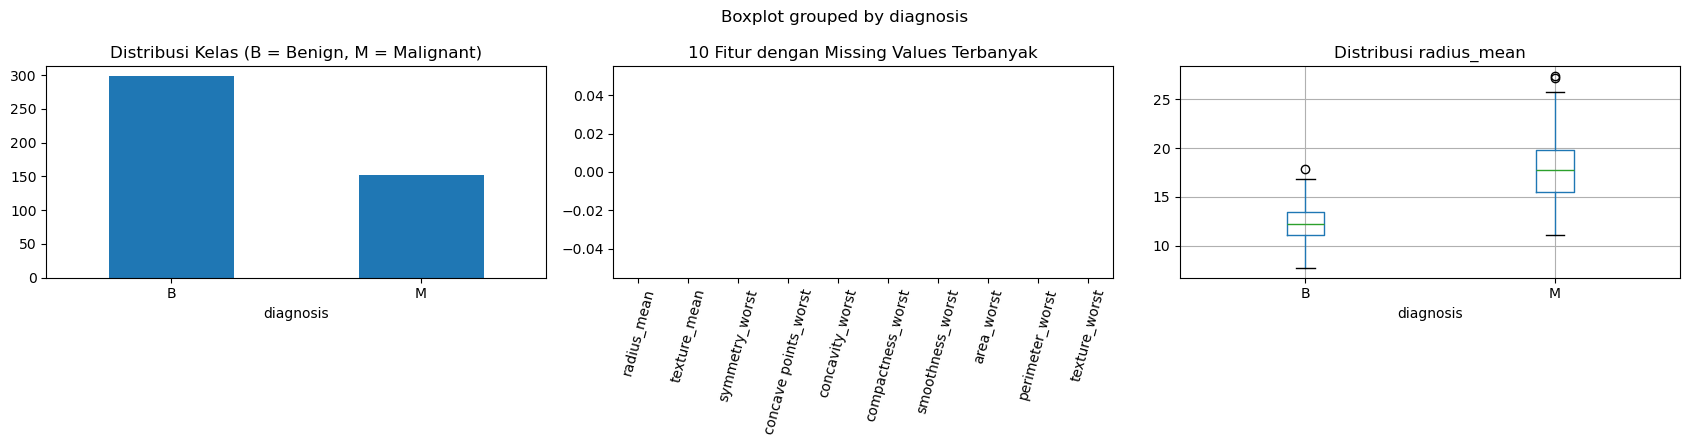

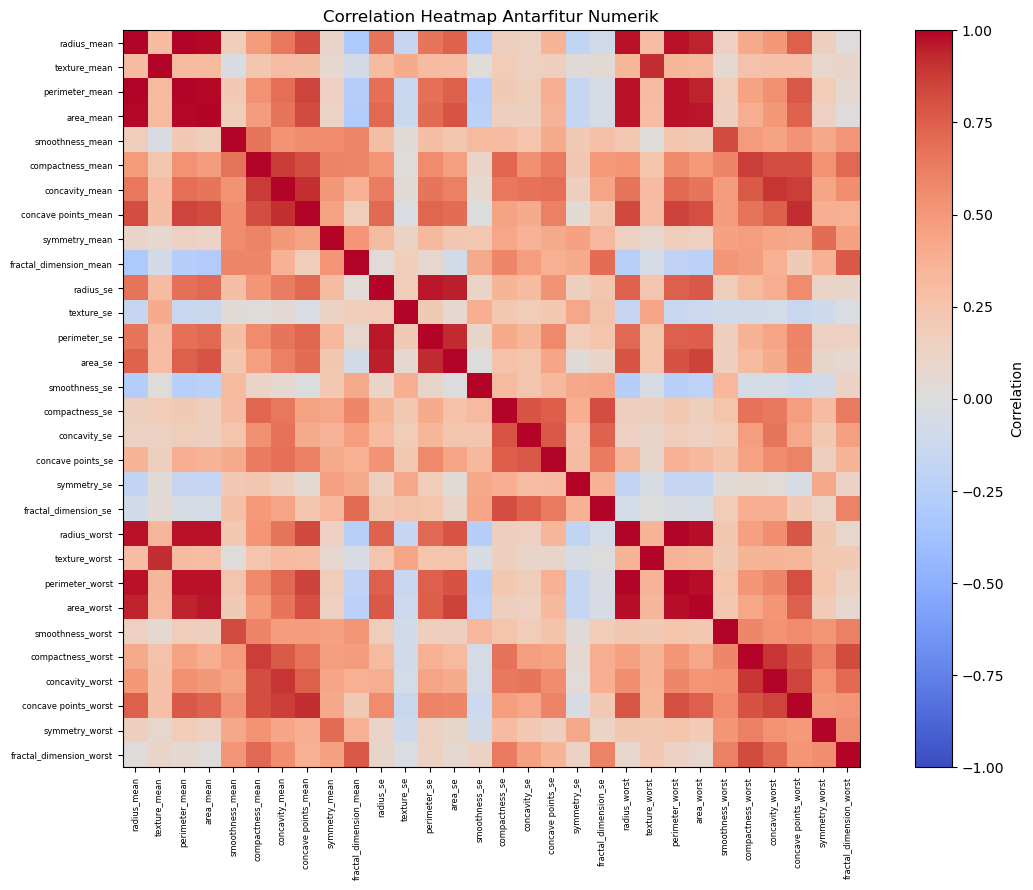

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
data_train['diagnosis'].value_counts().reindex(['B','M'], fill_value=0).plot(kind='bar', ax=axes[0], rot=0)
axes[0].set_title('Distribusi Kelas (B = Benign, M = Malignant)')
missing_counts = data_train[feature_cols].isna().sum().sort_values(ascending=False)
missing_counts.head(10).plot(kind='bar', ax=axes[1])
axes[1].set_title('10 Fitur dengan Missing Values Terbanyak')
axes[1].tick_params(axis='x', rotation=75)

# Dua fitur contoh untuk visualisasi distribusi per kelas.
example_col = 'radius_mean' if 'radius_mean' in feature_cols else feature_cols[0]
data_train.boxplot(column=example_col, by='diagnosis', ax=axes[2])
axes[2].set_title(f'Distribusi {example_col}')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 9))
corr = data_train[feature_cols].corr()
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Correlation')
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90, fontsize=6)
plt.yticks(range(len(corr.index)), corr.index, fontsize=6)
plt.title('Correlation Heatmap Antarfitur Numerik')
plt.tight_layout()
plt.show()

## 6. Penentuan Fitur dan Visualisasi PCA

Sebanyak 30 fitur numerik digunakan sebagai prediktor, sedangkan `diagnosis` menjadi target klasifikasi. *Principal Component Analysis* (PCA) mereduksi fitur menjadi dua komponen untuk menampilkan sebaran kelas secara visual. Model perbandingan tetap menggunakan fitur asli, bukan dua komponen PCA.

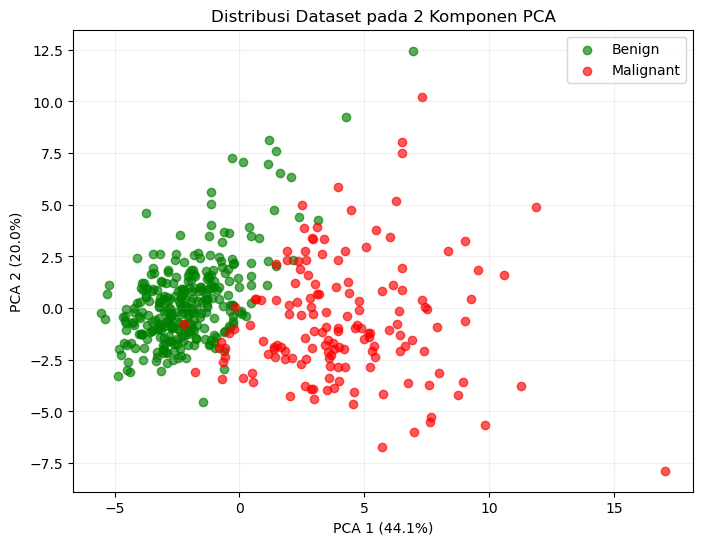

In [6]:
fitur_train = data_train[feature_cols]
label_train = data_train['diagnosis'].to_numpy()
fitur_test = data_test[feature_cols]

# PCA hanya untuk visualisasi, bukan data input model pembanding.
# Fit eksplorasi di data train saja; imputasi dan scaling yang digunakan model
# di bawah akan di-fit ulang hanya pada subset pelatihan setiap model.
pca_imputer = SimpleImputer(strategy='median')
pca_scaler = StandardScaler()
X_pca_input = pca_scaler.fit_transform(pca_imputer.fit_transform(fitur_train))
pca = PCA(n_components=2, random_state=RANDOM_STATE)
x_train_pca = pca.fit_transform(X_pca_input)

plt.figure(figsize=(8, 6))
for diagnosis, color, label in [('B', 'green', 'Benign'), ('M', 'red', 'Malignant')]:
    mask = label_train == diagnosis
    plt.scatter(x_train_pca[mask, 0], x_train_pca[mask, 1], c=color, label=label, alpha=0.65)
plt.xlabel(f'PCA 1 ({pca.explained_variance_ratio_[0]:.1%})')
plt.ylabel(f'PCA 2 ({pca.explained_variance_ratio_[1]:.1%})')
plt.title('Distribusi Dataset pada 2 Komponen PCA')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 7. Pembagian Data Pelatihan dan Validasi

Data berlabel dibagi secara *stratified* menjadi **70% data pelatihan** dan **30% data validasi**. Teknik ini menjaga proporsi kelas B dan M pada kedua bagian. Pembagian yang sama dipakai pada seluruh model agar evaluasinya dapat dibandingkan secara adil.

In [7]:
# Stratify menjaga proporsi B/M di kedua bagian.
X_train, X_test, y_train, y_test = train_test_split(
    fitur_train, label_train, test_size=0.30,
    random_state=RANDOM_STATE, stratify=label_train
)
encoder = LabelEncoder()
y_train_enc = encoder.fit_transform(y_train)
y_test_enc = encoder.transform(y_test)
print('Urutan kelas:', encoder.classes_, '(0=B, 1=M)')
print('Training:', X_train.shape, 'Validation:', X_test.shape)
print('Proporsi kelas training:', pd.Series(y_train).value_counts(normalize=True).to_dict())
print('Proporsi kelas validation:', pd.Series(y_test).value_counts(normalize=True).to_dict())

Urutan kelas: ['B' 'M'] (0=B, 1=M)
Training: (315, 30) Validation: (135, 30)
Proporsi kelas training: {'B': 0.6634920634920635, 'M': 0.33650793650793653}
Proporsi kelas validation: {'B': 0.6592592592592592, 'M': 0.34074074074074073}


## 8. Pengembangan Model Machine Learning

Lima algoritma dievaluasi: **SVM linear** sebagai model dasar, **k-NN** sebagai metode berbasis kedekatan, **Random Forest** dan **XGBoost** sebagai metode berbasis pohon, serta **ANN (MLP)** sebagai jaringan saraf multilapis. Setiap model dilatih menggunakan data dan pembagian validasi yang sama.

Imputasi median diterapkan pada setiap *pipeline*. Standardisasi fitur digunakan untuk SVM, k-NN, dan ANN yang sensitif terhadap skala. Random Forest dan XGBoost menggunakan fitur hasil imputasi tanpa standardisasi. Pengaturan model bersifat contoh awal, bukan hasil *hyperparameter tuning* menyeluruh.

In [8]:
models = {
    'SVM (Linear)': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', SVC(kernel='linear', probability=True, random_state=RANDOM_STATE))
    ]),
    'k-NN': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(n_neighbors=5))
    ]),
    'Random Forest': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))
    ]),
    'XGBoost': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', XGBClassifier(n_estimators=150, max_depth=3, learning_rate=0.05,
                                objective='binary:logistic', eval_metric='logloss',
                                random_state=RANDOM_STATE, n_jobs=2))
    ]),
    'ANN (MLP)': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu',
                                max_iter=1000, early_stopping=True,
                                random_state=RANDOM_STATE))
    ])
}

# Konversi target menjadi 0/1 agar semua estimator (termasuk XGBoost) kompatibel.
results = []
trained_models = {}
predictions = {}
for name, pipeline in models.items():
    pipeline.fit(X_train, y_train_enc)
    y_pred_num = pipeline.predict(X_test)
    y_score = pipeline.predict_proba(X_test)[:, 1]
    cm = confusion_matrix(y_test_enc, y_pred_num, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test_enc, y_pred_num),
        'Precision (M)': precision_score(y_test_enc, y_pred_num, zero_division=0),
        'Recall/Sensitivity (M)': recall_score(y_test_enc, y_pred_num, zero_division=0),
        'Specificity (B)': tn / (tn + fp) if (tn + fp) else np.nan,
        'F1-score (M)': f1_score(y_test_enc, y_pred_num, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test_enc, y_score)
    })
    trained_models[name] = pipeline
    predictions[name] = y_pred_num

comparison_df = pd.DataFrame(results).sort_values(
    by=['F1-score (M)', 'ROC-AUC', 'Accuracy'], ascending=False
).reset_index(drop=True)
display(comparison_df.style.format({c: '{:.4f}' for c in comparison_df.columns if c != 'Model'}))

C:\Users\Tiaravib\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Model,Accuracy,Precision (M),Recall/Sensitivity (M),Specificity (B),F1-score (M),ROC-AUC
0,SVM (Linear),0.9778,0.9778,0.9565,0.9888,0.9670,0.9861
1,XGBoost,0.9704,0.9773,0.9348,0.9888,0.9556,0.9816
2,k-NN,0.9704,1.0000,0.9130,1.0000,0.9545,0.9629
3,Random Forest,0.9630,0.9767,0.9130,0.9888,0.9438,0.9922
4,ANN (MLP),0.8741,0.9394,0.6739,0.9775,0.7848,0.9558


## 9. Evaluasi dan Perbandingan Performa

Kinerja model diukur menggunakan **accuracy, precision, recall/sensitivity, specificity, F1-score**, dan **ROC-AUC**. Kelas M (*malignant*) ditetapkan sebagai kelas positif. *Confusion matrix* digunakan untuk memeriksa kesalahan klasifikasi. Pemilihan model terbaik mengutamakan F1-score kelas M, kemudian ROC-AUC dan akurasi jika diperlukan.

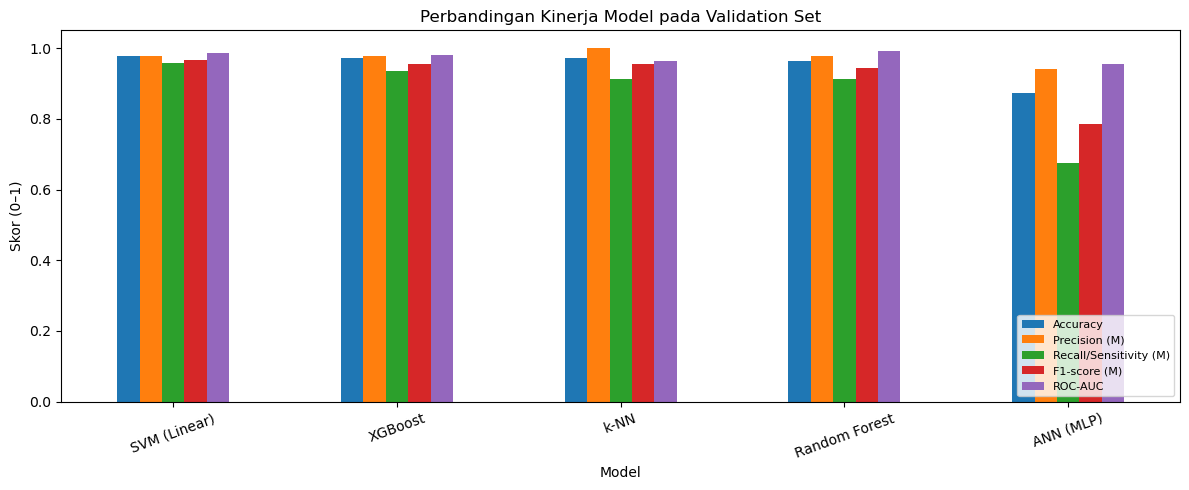

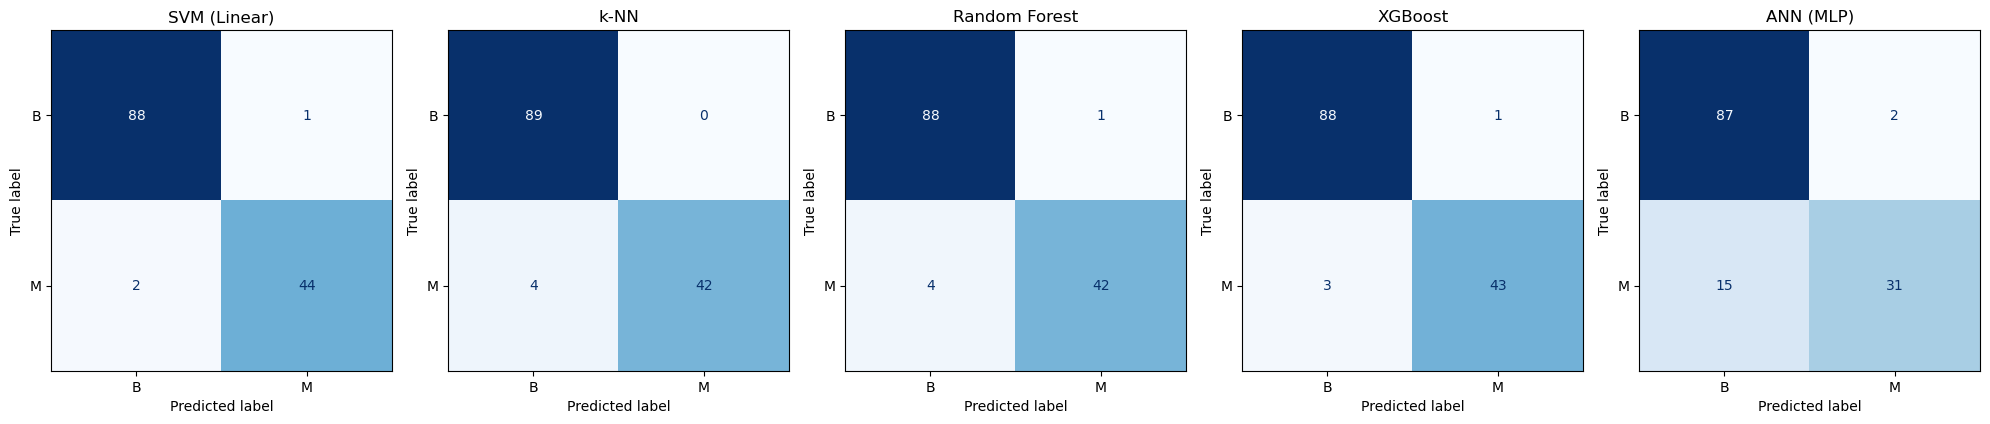

Model terbaik berdasar F1 kelas M → ROC-AUC → Accuracy: SVM (Linear)

Classification report model terbaik:
               precision    recall  f1-score   support

   B (Benign)       0.98      0.99      0.98        89
M (Malignant)       0.98      0.96      0.97        46

     accuracy                           0.98       135
    macro avg       0.98      0.97      0.98       135
 weighted avg       0.98      0.98      0.98       135



In [9]:
metric_cols = ['Accuracy', 'Precision (M)', 'Recall/Sensitivity (M)', 'F1-score (M)', 'ROC-AUC']
ax = comparison_df.set_index('Model')[metric_cols].plot(kind='bar', figsize=(12, 5), ylim=(0, 1.05), rot=20)
ax.set_title('Perbandingan Kinerja Model pada Validation Set')
ax.set_ylabel('Skor (0–1)')
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(trained_models), figsize=(20, 4))
for ax, (name, y_pred_num) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test_enc, y_pred_num, labels=[0, 1], display_labels=['B', 'M'],
        cmap='Blues', colorbar=False, ax=ax
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

best_name = comparison_df.loc[0, 'Model']
print('Model terbaik berdasar F1 kelas M → ROC-AUC → Accuracy:', best_name)
print('\nClassification report model terbaik:')
print(classification_report(y_test_enc, predictions[best_name], target_names=['B (Benign)', 'M (Malignant)'], zero_division=0))

## 10. Interpretasi Model SVM Linear

Koefisien SVM menunjukkan kontribusi relatif fitur setelah standardisasi, tetapi tidak otomatis membuktikan hubungan sebab-akibat. Visualisasi batas keputusan dua dimensi dibuat melalui model SVM terpisah pada ruang PCA untuk memudahkan interpretasi pola pemisahan kelas.

**Catatan metodologis:** grafik batas keputusan PCA hanya merupakan ilustrasi model dua dimensi. Grafik tersebut bukan batas keputusan identik dari model SVM utama yang menggunakan seluruh fitur.

Intercept: -0.5382054080152336
10 koefisien SVM standar dengan nilai absolut tertinggi:


,Coefficient
texture_worst,1.169298
concave points_mean,0.988247
radius_worst,0.723253
concavity_mean,0.714079
concavity_worst,0.697867
radius_se,0.660826
compactness_se,-0.603325
area_worst,0.581173
smoothness_worst,0.545186
texture_se,-0.520086


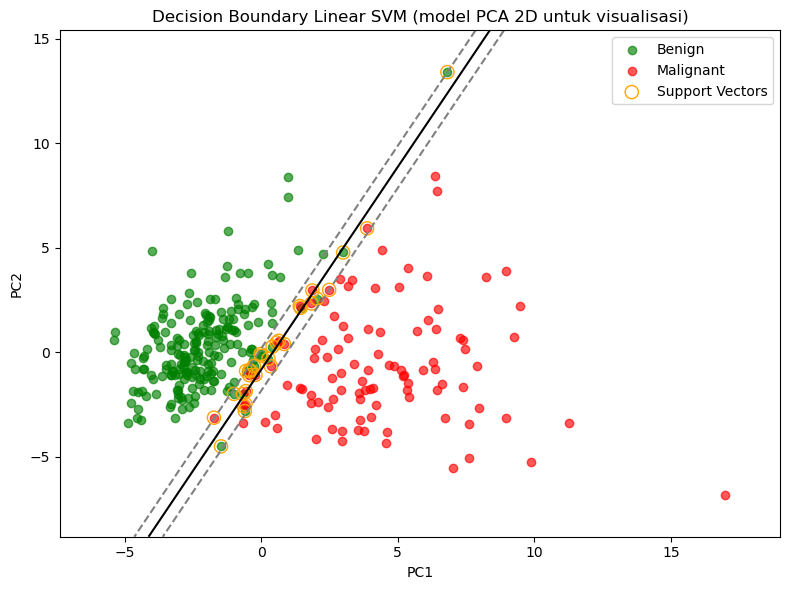

In [10]:
svc = trained_models['SVM (Linear)']
w = svc.named_steps['model'].coef_[0]
b = svc.named_steps['model'].intercept_[0]
coef_df = pd.Series(w, index=feature_cols).sort_values(key=np.abs, ascending=False)
print('Intercept:', b)
print('10 koefisien SVM standar dengan nilai absolut tertinggi:')
display(coef_df.head(10).rename('Coefficient').to_frame())

# Visualisasi boundary hanya berdasarkan train fold agar tidak terjadi leakage.
vis_imputer = SimpleImputer(strategy='median')
vis_scaler = StandardScaler()
vis_pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_vis = vis_pca.fit_transform(vis_scaler.fit_transform(vis_imputer.fit_transform(X_train)))
svc_2d = SVC(kernel='linear', random_state=RANDOM_STATE).fit(X_vis, y_train_enc)
x_min, x_max = X_vis[:, 0].min() - 2, X_vis[:, 0].max() + 2
y_min, y_max = X_vis[:, 1].min() - 2, X_vis[:, 1].max() + 2
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))
zz = svc_2d.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
plt.figure(figsize=(8, 6))
plt.contour(xx, yy, zz, levels=[-1, 0, 1], colors=['gray', 'black', 'gray'],
            linestyles=['--', '-', '--'])
plt.scatter(X_vis[y_train_enc == 0, 0], X_vis[y_train_enc == 0, 1], c='green', alpha=.65, label='Benign')
plt.scatter(X_vis[y_train_enc == 1, 0], X_vis[y_train_enc == 1, 1], c='red', alpha=.65, label='Malignant')
plt.scatter(svc_2d.support_vectors_[:, 0], svc_2d.support_vectors_[:, 1],
            facecolors='none', edgecolors='orange', s=90, label='Support Vectors')
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.title('Decision Boundary Linear SVM (model PCA 2D untuk visualisasi)')
plt.legend(); plt.tight_layout(); plt.show()

## 11. Prediksi Data Pengujian

Model dilatih kembali menggunakan seluruh sampel data latih yang memiliki label. Model terpilih kemudian digunakan untuk menghasilkan label B/M pada 120 sampel tanpa label. Prediksi ini belum dapat dinilai akurasinya karena *ground truth* data pengujian tidak tersedia.

Hasil prediksi setiap algoritma dan probabilitas kelas M disimpan untuk kebutuhan perbandingan. Probabilitas model merupakan estimasi algoritmik, bukan probabilitas diagnosis klinis.

In [11]:
y_full_num = encoder.transform(label_train)
final_models = {}
all_preds = pd.DataFrame({'id': data_test['id']})
for name, pipeline in models.items():
    pipeline.fit(fitur_train, y_full_num)
    final_models[name] = pipeline
    pred_num = pipeline.predict(fitur_test)
    all_preds[name] = encoder.inverse_transform(pred_num)
    all_preds[f'Prob_M_{name}'] = pipeline.predict_proba(fitur_test)[:, 1]

# Gunakan model terbaik berdasarkan validation score (pemilihan model dilakukan di validation set).
y_pred_test = all_preds[best_name].to_numpy()
hasil = pd.DataFrame({'id': data_test['id'], 'diagnosis': y_pred_test})
display(hasil.head())
print('Jumlah prediksi:', len(hasil), '| Model terpilih:', best_name)

C:\Users\Tiaravib\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,id,diagnosis
0,84799002,M
1,848406,M
2,84862001,M
3,849014,M
4,8510426,B


Jumlah prediksi: 120 | Model terpilih: SVM (Linear)


## 12. Penyimpanan Hasil Analisis

Tiga file keluaran disimpan pada direktori yang sama: `hasil_klasifikasi.csv` untuk label model terbaik, `perbandingan_model_ml.csv` untuk metrik evaluasi, dan `prediksi_semua_model.csv` untuk prediksi seluruh algoritma.

In [12]:
hasil.to_csv(output_path, index=False)
comparison_df.to_csv(comparison_path, index=False)
all_preds.to_csv(all_predictions_path, index=False)
print('File tersimpan:')
print('-', output_path)
print('-', comparison_path)
print('-', all_predictions_path)
print('\nDistribusi prediksi model terbaik:')
print(hasil['diagnosis'].value_counts())

File tersimpan:
- C:\Users\Tiaravib\Documents\Jupyter Notebook\Project Analytics\Contoh SVM Classifier\breastcancer_classification\hasil_klasifikasi.csv
- C:\Users\Tiaravib\Documents\Jupyter Notebook\Project Analytics\Contoh SVM Classifier\breastcancer_classification\perbandingan_model_ml.csv
- C:\Users\Tiaravib\Documents\Jupyter Notebook\Project Analytics\Contoh SVM Classifier\breastcancer_classification\prediksi_semua_model.csv

Distribusi prediksi model terbaik:
diagnosis
M    60
B    60
Name: count, dtype: int64


## 13. Kesimpulan

Notebook pengembangan memperluas analisis SVM tunggal menjadi alur klasifikasi yang mencakup pemeriksaan kualitas data, EDA, pemrosesan yang mengurangi risiko *data leakage*, dan perbandingan lima algoritma. Hasil validasi menunjukkan performa relatif masing-masing model pada pembagian data yang digunakan. Generalisasi pada dataset lain masih memerlukan validasi tambahan.

**Keterbatasan:** evaluasi menggunakan satu pembagian *train–validation* dan tidak melibatkan validasi eksternal atau pencarian hiperparameter sistematis. Hasil ini ditujukan untuk demonstrasi analisis *machine learning*, bukan penggunaan klinis.